# 06 · Đánh giá

Đọc kết quả đã lưu sau `python -m student_success.train`. Test chỉ đánh giá sau khi chọn tham số trên CV; các điểm là một lần chia.

Notebook chạy độc lập từ thư mục gốc hoặc `notebooks/`; cài `requirements-demo.txt` trước.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT/'student_success').exists(): ROOT = ROOT.parent
assert (ROOT/'student_success').exists(), 'Chạy từ thư mục dự án hoặc notebooks/'
sys.path.insert(0, str(ROOT))
from student_success.data import CATEGORICAL, NUMERIC, LABELS, SEED, split
DATA = ROOT/'data/raw/data.csv'
assert DATA.exists(), 'Chạy python scripts/download_data.py'
df = pd.read_csv(DATA, sep=';'); df.columns = df.columns.str.strip()
train_idx, test_idx = split(df)
train = df.loc[train_idx]
R = ROOT/'data/experiment'


,model,accuracy,macro_precision,macro_recall,macro_f1,dropout_recall
0,A_knn,0.490395,0.394380,0.402397,0.395508,0.461268
1,A_tree,0.527684,0.445139,0.442301,0.439327,0.485915
2,B_knn,0.554802,0.440026,0.441692,0.427908,0.475352
3,B_tree,0.493785,0.462192,0.457258,0.451668,0.373239


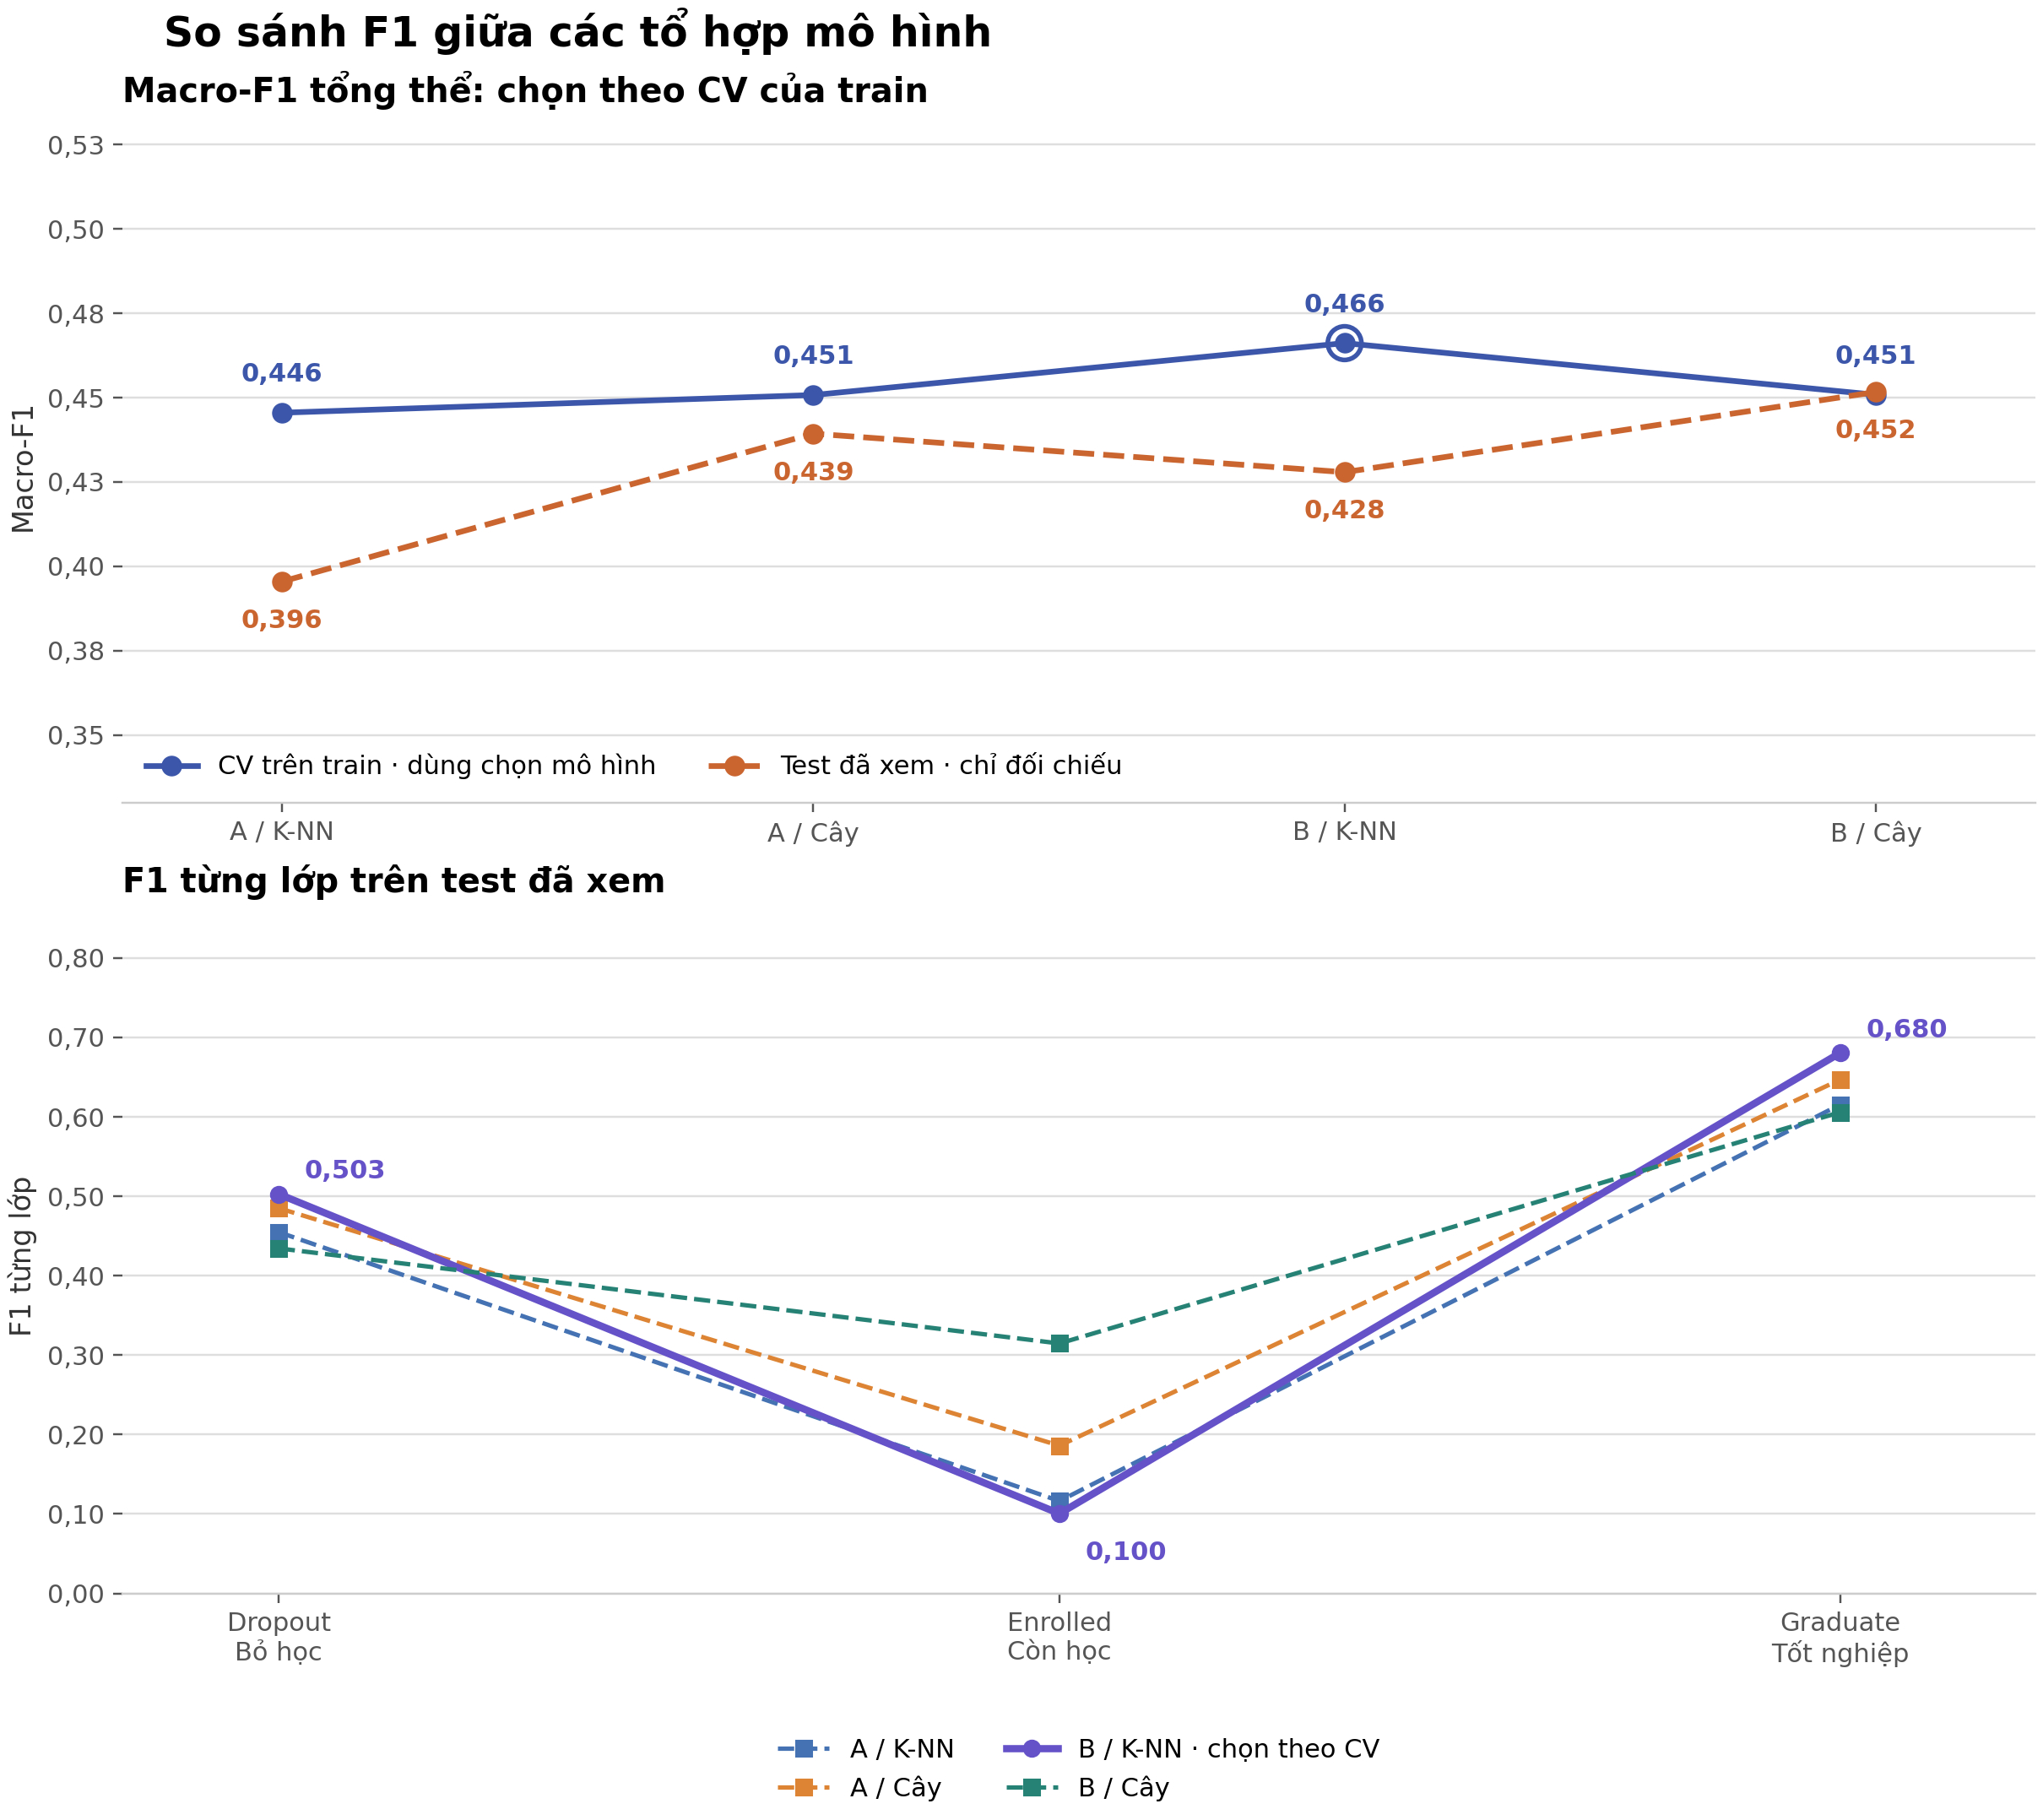

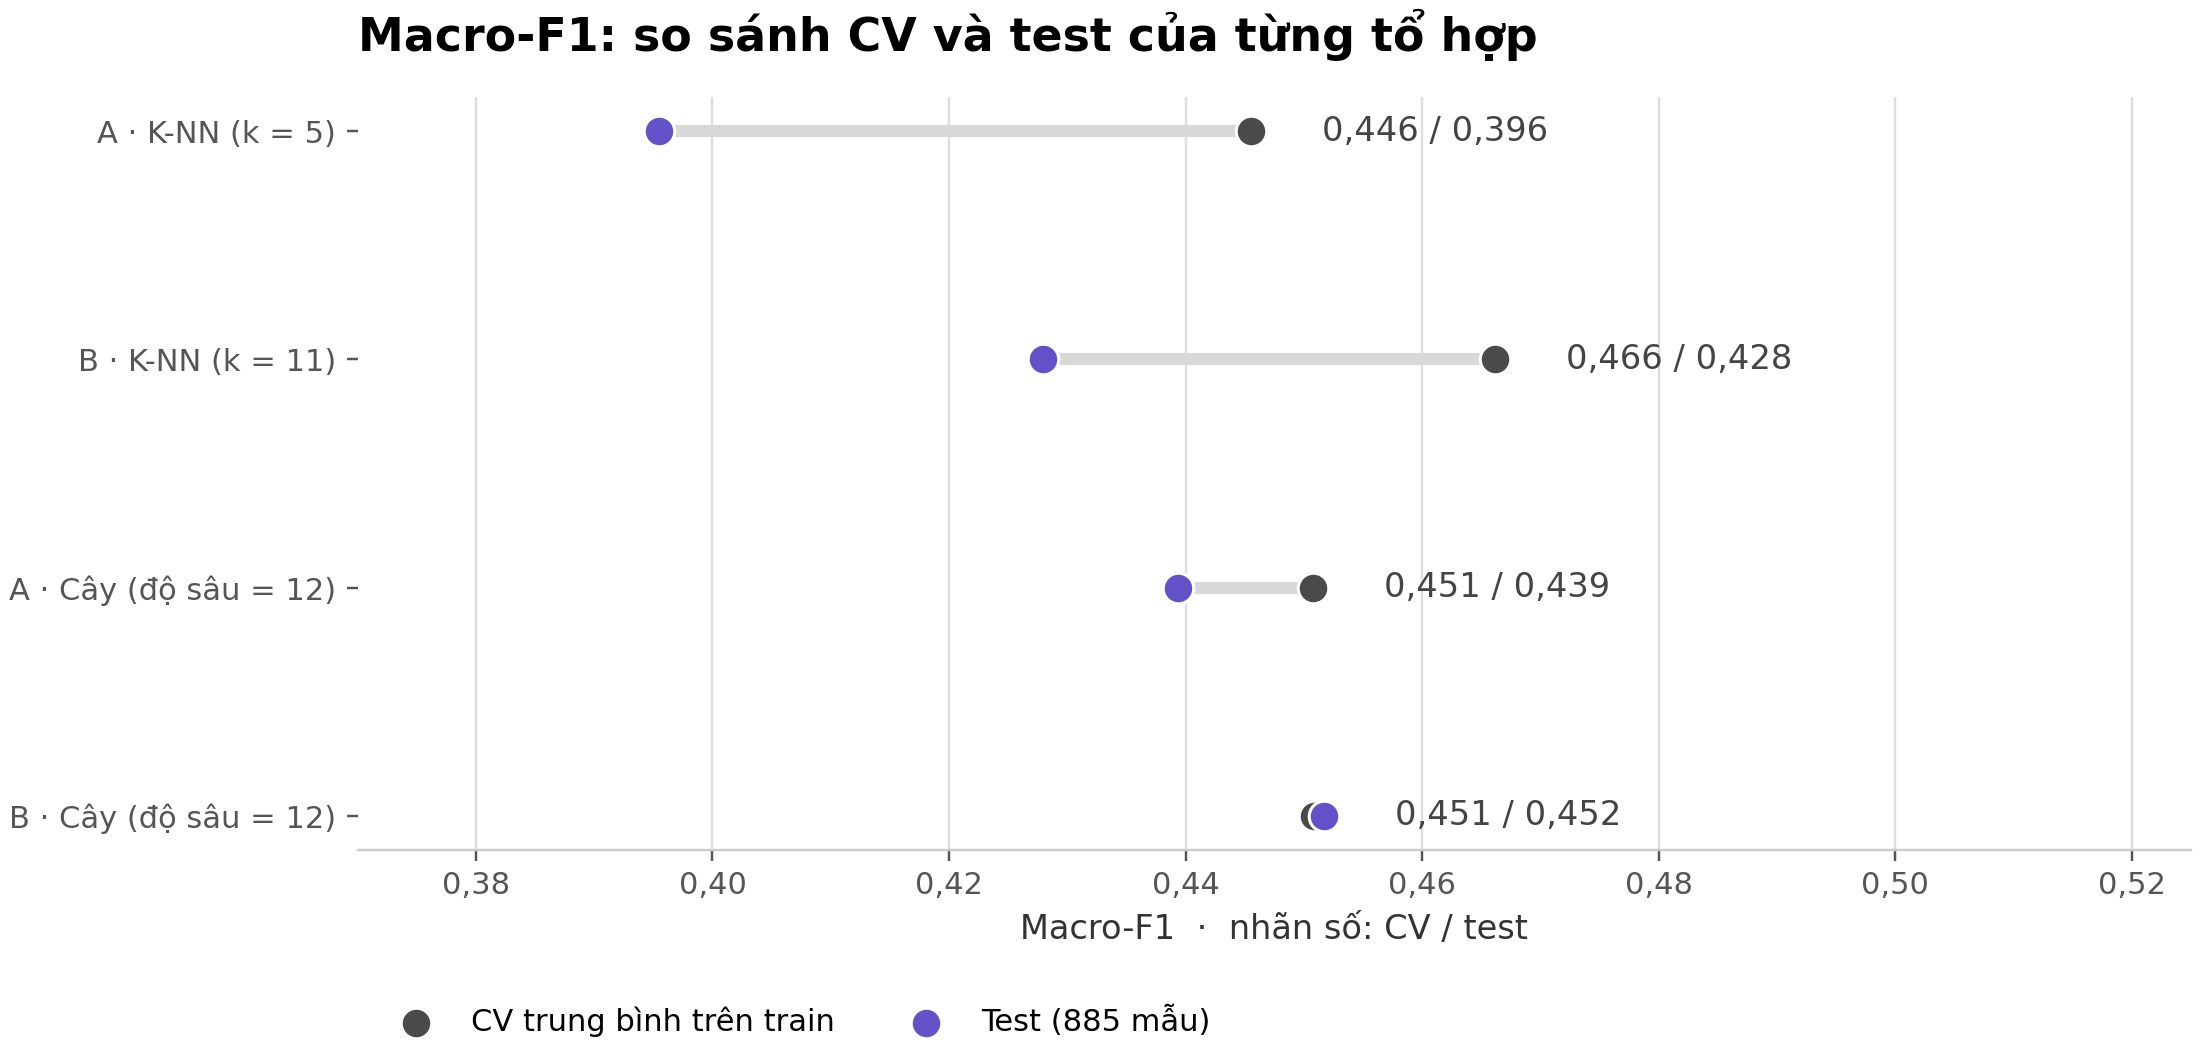

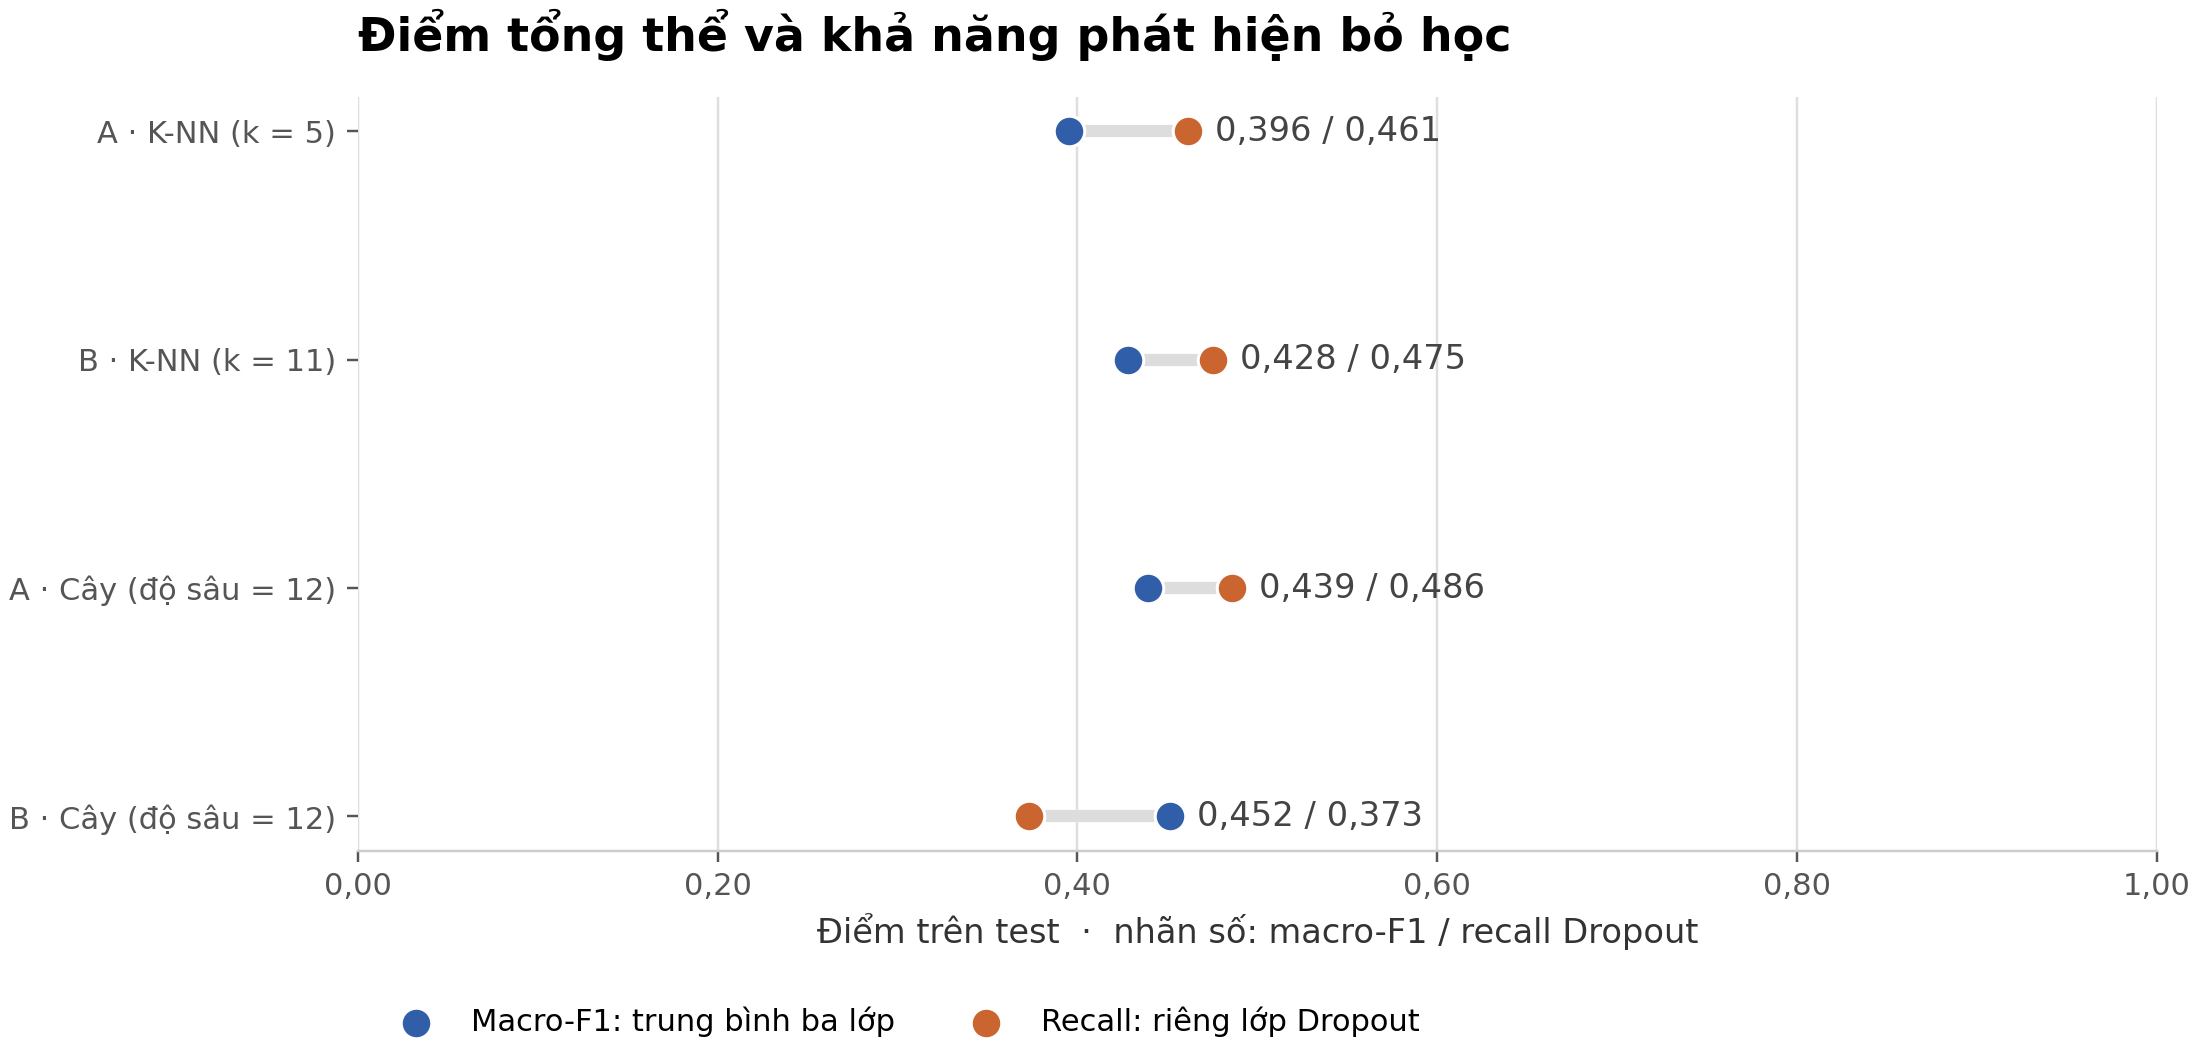

In [2]:
summary=pd.read_csv(R/'summary.csv'); display(summary)
from IPython.display import Image
display(Image(filename=str(ROOT/'report/course-template/images/results/f1_algorithms.png')))
display(Image(filename=str(ROOT/'report/course-template/images/results/cv_test_comparison.png')))
display(Image(filename=str(ROOT/'report/course-template/images/results/comparison.png')))

In [3]:
reports=[]
for name in ['A_knn','A_tree','B_knn','B_tree']:
    t=pd.read_csv(R/f'{name}_classification_report.csv',index_col=0).loc[LABELS].copy()
    t.insert(0,'Tổ hợp',name); reports.append(t.rename_axis('Lớp').reset_index())
display(pd.concat(reports,ignore_index=True))

,Lớp,Tổ hợp,precision,recall,f1-score,support
0,Dropout,A_knn,0.448630,0.461268,0.454861,284.0
1,Enrolled,A_knn,0.151515,0.094340,0.116279,159.0
2,Graduate,A_knn,0.582996,0.651584,0.615385,442.0
3,Dropout,A_tree,0.484211,0.485915,0.485062,284.0
4,Enrolled,A_tree,0.242424,0.150943,0.186047,159.0
5,Graduate,A_tree,0.608782,0.690045,0.646872,442.0
6,Dropout,B_knn,0.533597,0.475352,0.502793,284.0
7,Enrolled,B_knn,0.183333,0.069182,0.100457,159.0
8,Graduate,B_knn,0.603147,0.780543,0.680473,442.0
9,Dropout,B_tree,0.519608,0.373239,0.434426,284.0


## Baseline, ablation và khoảng biến thiên
Chạy `python scripts/evidence_analysis.py` và `python scripts/roc_analysis.py` để tạo các bảng. Bootstrap mô tả test đã xem và không thay thế tập test độc lập.

In [4]:
for filename in ['default_baselines.csv','ablation_cv.csv','test_bootstrap_ci.csv','B_knn_roc_auc.csv']:
    print(filename)
    display(pd.read_csv(R/filename))

default_baselines.csv


,model,cv_f1_mean,cv_f1_std,test_accuracy,test_macro_f1,test_macro_precision,test_macro_recall,test_dropout_recall
0,knn,0.440061,0.013966,0.497175,0.412637,0.417943,0.415143,0.440141
1,tree,0.424103,0.020454,0.482486,0.434659,0.434323,0.435792,0.436620


ablation_cv.csv


,model,variant,macro_f1_cv_mean,macro_f1_cv_std,fold_0,fold_1,fold_2,fold_3,fold_4
0,B_knn,full_B,0.466146,0.016841,0.477482,0.484896,0.467311,0.435548,0.465493
1,B_knn,no_rare_grouping,0.458536,0.012086,0.474500,0.456980,0.469939,0.443397,0.447863
2,B_knn,no_age_band,0.447969,0.020009,0.472041,0.459510,0.455917,0.414415,0.437964
3,B_knn,no_grade_difference,0.465485,0.013762,0.479609,0.480493,0.467330,0.445576,0.454419
4,B_knn,no_engineered,0.452891,0.010990,0.465823,0.462306,0.456401,0.439121,0.440803
5,B_tree,full_B,0.450840,0.020219,0.452047,0.447381,0.488098,0.437208,0.429468
6,B_tree,no_rare_grouping,0.436871,0.008845,0.445858,0.432843,0.446483,0.436501,0.422670
7,B_tree,no_age_band,0.449290,0.018886,0.451622,0.441362,0.484775,0.436495,0.432195
8,B_tree,no_grade_difference,0.447132,0.013808,0.445208,0.430374,0.467707,0.457224,0.435150
9,B_tree,no_engineered,0.448115,0.016862,0.459300,0.424772,0.470850,0.452283,0.433371


test_bootstrap_ci.csv


,model,macro_f1,ci_low,ci_high,iterations,seed
0,A_knn,0.395508,0.364863,0.426158,2000,42
1,A_tree,0.439327,0.405936,0.470394,2000,42
2,B_knn,0.427908,0.398081,0.457620,2000,42
3,B_tree,0.451668,0.417421,0.482987,2000,42


B_knn_roc_auc.csv


,dataset,Dropout,Enrolled,Graduate,macro_ovr
0,train_oof,0.701731,0.596090,0.694092,0.663971
1,test_viewed,0.684051,0.577391,0.668450,0.643297
